# 03 - Baseline Modeling
**Goal:** Build a logistic regression pipeline and evaluate it with metrics suited to imbalanced data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

os.makedirs("../images", exist_ok=True)
df = pd.read_csv("../data/cleaned_churn.csv")

# Safety checks
assert df.isnull().sum().sum() == 0
assert set(df['Churn'].unique()) == {0, 1}
print(df.shape)

(7043, 20)


In [2]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train:", y_train.mean().round(3), " test:", y_test.mean().round(3))

Train: (5634, 19)  Test: (1409, 19)
Churn rate train: 0.265  test: 0.265


In [3]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]
print(len(cat_cols), "categorical columns:", cat_cols)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

16 categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [4]:
preprocess.fit(X_train)
print("Columns after encoding:", preprocess.transform(X_train).shape[1])

Columns after encoding: 39


In [6]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred_dummy), 3))
print("Recall   :", recall_score(y_test, pred_dummy))
print("Precision:", precision_score(y_test, pred_dummy, zero_division=0))

Accuracy : 0.735
Recall   : 0.0
Precision: 0.0


In [8]:
log_reg = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000))
])
log_reg.fit(X_train, y_train)

pred = log_reg.predict(X_test)
proba = log_reg.predict_proba(X_test)[:, 1]
print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Recall   : {recall_score(y_test, pred):.3f}")
print(f"F1       : {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, proba):.3f}")

Accuracy : 0.806
Precision: 0.657
Recall   : 0.559
F1       : 0.604
ROC-AUC  : 0.842


[[926 109]
 [165 209]]


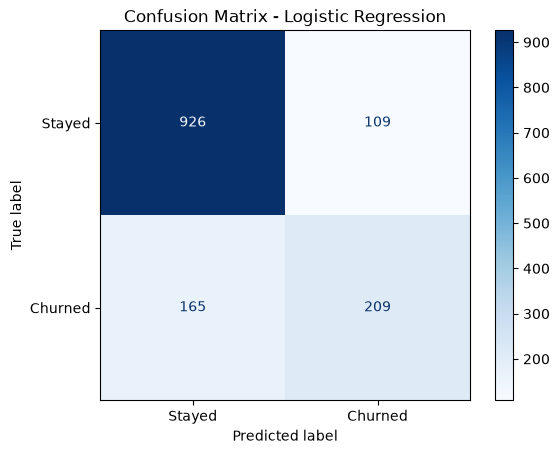

In [9]:
cm = confusion_matrix(y_test, pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Logistic Regression")
plt.savefig("../images/07_confusion_matrix_baseline.png", dpi=150, bbox_inches='tight')
plt.show()

In [10]:
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



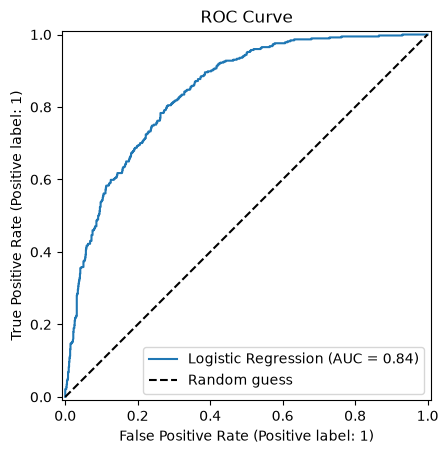

In [11]:
RocCurveDisplay.from_predictions(y_test, proba, name="Logistic Regression")
plt.plot([0, 1], [0, 1], 'k--', label="Random guess")
plt.title("ROC Curve")
plt.legend()
plt.savefig("../images/08_roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()

In [14]:
log_bal = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])
log_bal.fit(X_train, y_train)
pred_bal = log_bal.predict(X_test)
proba_bal = log_bal.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred_bal, target_names=['Stayed', 'Churned']))
print(f"ROC-AUC: {roc_auc_score(y_test, proba_bal):.3f}")

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842


In [15]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    rows.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, p),
        'precision': precision_score(y_test, p),
        'recall': recall_score(y_test, p),
        'f1': f1_score(y_test, p)
    })
pd.DataFrame(rows).round(3)

,threshold,accuracy,precision,recall,f1
0,0.2,0.705,0.470,0.858,0.607
1,0.3,0.751,0.521,0.757,0.617
2,0.4,0.779,0.572,0.671,0.617
3,0.5,0.806,0.657,0.559,0.604
4,0.6,0.800,0.719,0.404,0.517


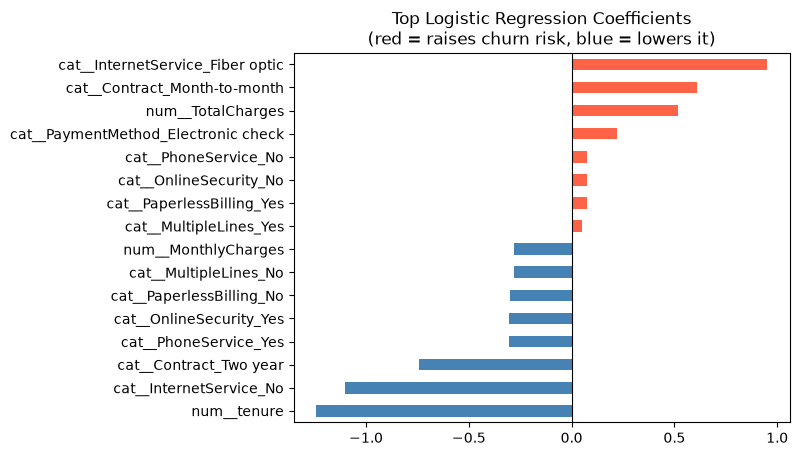

In [16]:
names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['model'].coef_[0], index=names)

top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])
top.plot(kind='barh', color=['steelblue' if v < 0 else 'tomato' for v in top])
plt.title("Top Logistic Regression Coefficients\n(red = raises churn risk, blue = lowers it)")
plt.axvline(0, color='black', linewidth=0.8)
plt.savefig("../images/09_coefficients.png", dpi=150, bbox_inches='tight')
plt.show()

## Results (test set, 1,409 customers)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (always "No") | 0.735 | 0.00 | 0.00 | 0.00 | 0.50 |
| Logistic Regression | 0.81 | 0.67 | 0.56 | 0.61 | 0.84 |
| Logistic Regression (balanced) | 0.75 | 0.52 | 0.79 | 0.63 | 0.84 |

## Takeaways
- Accuracy alone is misleading: 73.5% is achievable by predicting nobody churns.
- The baseline logistic regression misses ~44% of churners (recall 0.56).
- Class weighting raises recall to ~0.79 at the cost of more false alarms, which suits a retention use case where a lost customer costs more than a discount offer.
- Top drivers match the EDA: month-to-month contracts, short tenure, fiber optic, and electronic check payments.
- Next: try tree-based models, cross-validation, and hyperparameter tuning.